In [72]:
# load packages
import geopandas as gpd
import pandas as pd
import folium

In [73]:
# your df should already exist from Stage 1, or re-load it from the CSV
df = pd.read_csv("exposure_data.csv")

In [74]:
# creating a geo-dataframe that stores lat and long in a POINT(long, lat) structure i.e. POINT(x, y)
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"])
)

gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552)
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143)
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607)
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161)
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778)
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807)
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303)
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589)
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662)
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313)


In [75]:
# and initial check of the points on a graph
#gdf.plot()

In [76]:
# adding a map for context

# create the base map
m = folium.Map(location=[-20, 147], zoom_start=5)

# loop through each row and add a marker
for idx, row in gdf.iterrows():
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=f"Policy {row['policy_id']}"  # try adding more info here if you want
    ).add_to(m)

m

In [77]:
# The points we plotted are randomly generated which is why some are out in the open ocean. 
# Instead, we can load a real QLD coastline to constrain our points.

## Option A: Natural Earth

In [78]:
# download from website and check for name of states
world_states = gpd.read_file("https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip")
world_states.columns

Index(['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2',
       'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt',
       ...
       'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT', 'FCLASS_NL',
       'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'FCLASS_TLC', 'geometry'],
      dtype='str', length=122)

In [ ]:
# check Queensland is an option to filter for
qld = world_states[world_states["name"] == "Queensland"]
qld


,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


In [80]:
# check Queensland is in Australia (i.e. there's no other QLDs in the world)

qld = world_states[(world_states["name"] == "Queensland") & (world_states["iso_a2"] == "AU")]
qld

,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


<Axes: >

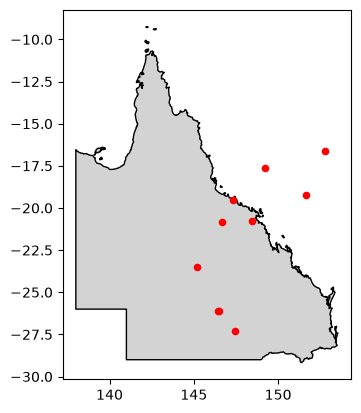

In [81]:
# plotting the QLD polygon and our randomly generated points.
# note that the geometry is a multipolygon as QLD also includes the islands 
# such as the Whitsundays which aren't connected to the mainland.

ax = qld.plot(color="lightgrey", edgecolor="black")
gdf.plot(ax=ax, color="red", markersize=20)

In [ ]:
# create a column to track which points are inside/outside the polygon
# 

gdf["in_qld"] = gdf.within(qld.union_all())
gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143),False
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607),False
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589),False
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [83]:
# counts the points in/out of QLD

gdf["in_qld"].value_counts()

in_qld
True     7
False    3
Name: count, dtype: int64